# Parte 2 – Evaluación y extracción estructurada

**Protocolo** (para que las métricas midan los modelos y no nuestros ajustes):
1. La muestra de 10 documentos y 10 clips, la región de evaluación, los parámetros de cada modelo, la normalización y la **regla de decisión** se fijaron y se commitearon **antes** de correr cualquier modelo sobre la muestra.
2. Las referencias (`texto_referencia`) son transcripciones **manuales y ciegas**: la estación de trabajo nunca mostró la salida de un modelo.
3. Todos los modelos se evalúan sobre los mismos 10 + 10 archivos, con la misma normalización. En audio, además, con los **mismos tramos de voz**.
4. Las métricas se calculan sobre el texto crudo, de forma local. Lo publicado (CSV, app) está seudonimizado.

In [1]:
import json, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import jiwer

RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ))
import ocr, privacidad as pv, extraccion as ex
import paleta

pio.templates.default = "paleta"
pio.renderers.default = "plotly_mimetype+png"
RAW = RAIZ / "datos" / "raw"
muestra = pd.read_csv(RAIZ / "datos" / "muestra_eval.csv")
config = json.loads((RAIZ / "modelos" / "configuraciones.json").read_text(encoding="utf-8"))
reemplazos = json.loads((RAW / "seudonimos.json").read_text(encoding="utf-8"))
historial = subprocess.run(["git", "log", "--format=%h %ci %s", "--", "datos/muestra_eval.csv", "modelos/configuraciones.json"],
                           capture_output=True, text=True, cwd=RAIZ).stdout
print("Commits que congelaron la muestra y las configuraciones:\n" + historial)
muestra.groupby(["modalidad", "estrato"]).size()

Commits que congelaron la muestra y las configuraciones:
cf9819d 2026-10-26 10:27:45 -0500 eval: registrar desviaciÃ³n por modelo Gemini saturado
5658bcb 2026-10-26 10:23:17 -0500 eval: muestra 10+10, recortes y configuraciones congeladas



modalidad  estrato              
audio      commons_calle            1
           commons_conferencia      1
           commons_estudiante       2
           commons_multihablante    1
           commons_testimonio       1
           openslr_hombre           2
           openslr_mujer            2
documento  foto                     3
           impreso                  3
           manuscrito_XIX           2
           manuscrito_XX            2
dtype: int64

In [2]:
# Títulos analíticos (se escriben después de ver los resultados)
TITULO_CER = "Gemini baja el CER de los manuscritos de 0.52–0.73 a 0.05–0.06, pero en las fotos pierde contra PaddleOCR (0.70 frente a 0.43)"
TITULO_WER = "La calle y la conversación de varios hablantes son lo más difícil: WER de 0.32 a 0.57, frente a 0.00–0.17 en lectura limpia"
TITULO_RTF = "Parakeet queda a 0.014 de WER de turbo y procesa 9 veces más rápido (RTF 0.27 frente a 2.54)"
TITULO_NER = "Perú y el Congreso son las entidades más mencionadas: el corpus mezcla normas oficiales y fútbol"


## 1. Muestra de evaluación y referencias manuales

- **Documentos:** se evalúa la región fijada de antemano, el **40 % superior de la página**, igual para todos los modelos.
- **Guía de transcripción:** literal y en orden de lectura; `[?]` para lo ilegible.
- Los `[?]` se excluyen de la métrica y se reportan.

In [3]:
ref = {i: (RAW / "referencias" / f"{i}.txt").read_text(encoding="utf-8").strip() for i in muestra.id
       if (RAW / "referencias" / f"{i}.txt").exists()}
info = pd.DataFrame([{"id": i, "palabras": len(t.split()), "ilegibles_[?]": t.count("[?]"),
                      "pct_[?]": round(100 * t.count("[?]") / max(1, len(t.split())), 1)} for i, t in ref.items()])
print(f"Referencias manuales disponibles: {len(ref)} de {len(muestra)}")
muestra.merge(info, on="id", how="left")

Referencias manuales disponibles: 20 de 20


,id,modalidad,estrato,palabras,ilegibles_[?],pct_[?]
0,doc_005,documento,impreso,56,0,0.0
1,doc_006,documento,impreso,118,0,0.0
2,doc_004,documento,impreso,122,0,0.0
3,doc_013,documento,foto,65,0,0.0
4,doc_014,documento,foto,30,2,6.7
5,doc_012,documento,foto,15,0,0.0
6,doc_018,documento,manuscrito_XX,43,0,0.0
7,doc_019,documento,manuscrito_XX,29,0,0.0
8,doc_023,documento,manuscrito_XIX,45,0,0.0
9,doc_024,documento,manuscrito_XIX,55,0,0.0


In [4]:
# Control de calidad del audio leído: referencia manual contra la frase original de OpenSLR (no reemplaza la referencia)
slr_txt = pd.read_csv(RAW / "audio" / "clips_openslr.csv").set_index("id")["texto_corpus"]
for i in muestra[muestra.estrato.str.startswith("openslr")].id:
    if i in ref:
        print(i, "diferencia con la frase del corpus:", round(jiwer.wer(ocr.limpiar_para_metrica(slr_txt[i]),
                                                                        ocr.limpiar_para_metrica(ref[i]) or "∅"), 3))

clip_086 diferencia con la frase del corpus: 0.0
clip_078 diferencia con la frase del corpus: 0.0
clip_146 diferencia con la frase del corpus: 0.0
clip_138 diferencia con la frase del corpus: 0.0


## 2. Predicciones de todos los modelos sobre la muestra

| Modalidad | Clave | Modelo | Rol |
|---|---|---|---|
| OCR | `paddle_base` | PaddleOCR 3.7 PP-OCRv6, configuración por defecto | **Línea base** |
| OCR | `paddle_sin_geo` | PaddleOCR sin orientación ni *unwarping* | Ablación |
| OCR | `gemini_vlm` | Gemini Flash como modelo de visión y lenguaje (transcripción literal) | Alternativa |
| ASR | `fw_small` | faster-whisper `small`, int8, CPU | **Línea base** |
| ASR | `fw_turbo` | faster-whisper large-v3-turbo, int8, CPU | Mismo modelo, más grande |
| ASR | `parakeet` | NVIDIA Parakeet TDT 0.6B v3 | Alternativa (otro ASR) |

In [5]:
p_ocr = pd.concat([pd.read_csv(RAW / "ocr" / "eval_predicciones.csv"),
                   pd.read_csv(RAW / "ocr" / "eval_gemini.csv").query("modelo == 'gemini_vlm'")], ignore_index=True)
p_asr = pd.read_csv(RAW / "asr" / "eval_predicciones.csv")
print("OCR:", p_ocr.groupby("modelo").id.nunique().to_dict(), "| ASR:", p_asr.groupby("modelo").id.nunique().to_dict())
print("Modelo de Gemini realmente usado:", p_ocr.get("modelo_real", pd.Series(dtype=str)).dropna().value_counts().to_dict())
assert all(set(g.id) == set(muestra[muestra.modalidad == m].id)
           for m, p in [("documento", p_ocr), ("audio", p_asr)] for _, g in p.groupby("modelo")), "modelos sobre muestras distintas"

OCR: {'gemini_vlm': 10, 'paddle_base': 10, 'paddle_sin_geo': 10} | ASR: {'fw_small': 10, 'fw_turbo': 10, 'parakeet': 10}
Modelo de Gemini realmente usado: {'gemini-3.6-flash': 8, 'gemini-3.5-flash-lite': 2}


## 3. Métricas: CER (documentos) y WER (audio)

- **Normalización** (`ocr.limpiar_para_metrica`, la misma para la referencia y para las hipótesis):
  - quita las marcas `[...]` (hablantes, seudónimos, `[?]`) y los prefijos `H1:`;
  - pasa los dígitos a palabras;
  - aplica `voz.normalizar`: minúsculas, sin puntuación, con tildes.
  - En WER, además, quita las muletillas de una lista fija.
- **Métrica oficial:** agregada, con jiwer sobre las 10 referencias juntas, así pesa más el texto largo. También se reporta la media por archivo y por estrato.

In [6]:
est = muestra.set_index("id").estrato
def tabla_metricas(pred, metrica, ids):
    filas = []
    for m, g in pred.groupby("modelo"):
        g = g.set_index("id").reindex([i for i in ids if i in ref])
        refs, hips = [ref[i] for i in g.index], g.texto.fillna("").tolist()
        por_archivo = [metrica([r], [h]) for r, h in zip(refs, hips)]
        filas.append({"modelo": m, "agregado": metrica(refs, hips), "media_por_archivo": float(np.mean(por_archivo)),
                      "seg_por_archivo": g.segundos.mean(), **({"rtf": g.rtf.mean(), "carga_seg": g.carga_seg.iloc[0]} if "rtf" in g else {})})
        for i, v in zip(g.index, por_archivo):
            detalle.append({"modelo": m, "id": i, "estrato": est[i], "valor": v})
    return pd.DataFrame(filas).round(3)

detalle = []
ids_doc, ids_aud = muestra[muestra.modalidad == "documento"].id, muestra[muestra.modalidad == "audio"].id
cer_t = tabla_metricas(p_ocr, ocr.cer, ids_doc)
wer_t = tabla_metricas(p_asr, ocr.wer, ids_aud)
det = pd.DataFrame(detalle)
cer_t["cer_lineas_ordenadas"] = [np.mean([ocr.cer_lineas_ordenadas(ref[i], t) for i, t in zip(g.id, g.texto.fillna("")) if i in ref])
                                 for _, g in p_ocr.groupby("modelo")]
print("CER por modelo (documentos):"); display(cer_t)
print("WER por modelo (audio):"); display(wer_t)

CER por modelo (documentos):

,modelo,agregado,media_por_archivo,seg_por_archivo,cer_lineas_ordenadas
0,gemini_vlm,0.138,0.252,22.773,0.442447
1,paddle_base,0.310,0.426,7.700,0.535671
2,paddle_sin_geo,0.323,0.484,7.478,0.538918


WER por modelo (audio):


,modelo,agregado,media_por_archivo,seg_por_archivo,rtf,carga_seg
0,fw_small,0.224,0.207,25.809,1.017,3.1
1,fw_turbo,0.125,0.110,62.347,2.537,7.7
2,parakeet,0.139,0.135,7.362,0.271,27.3


In [7]:
base_cer = cer_t.set_index("modelo").agregado["paddle_base"]
base_wer = wer_t.set_index("modelo").agregado["fw_small"]
print(f"LÍNEA BASE → CER PaddleOCR por defecto: {base_cer:.3f} | WER faster-whisper small (CPU): {base_wer:.3f}")

LÍNEA BASE → CER PaddleOCR por defecto: 0.310 | WER faster-whisper small (CPU): 0.224


## 4. Extracción estructurada con LLM

- **Esquema:** Pydantic (`extraccion.py`) enviado como `response_schema`.
  - Campos comunes: `modalidad`, `tema`, `resumen`.
  - Documentos: `tipo_documento`, `emisor`, `destinatario`, `fecha`, `lugar`, `monto`.
  - Audio: `numero_hablantes`, `lugar`, `citas_clave{hablante, cita}`.
- **Regla del prompt:** `null` si el dato no aparece; no inventar.
- **Entrada:** el texto **seudonimizado**, así el LLM nunca ve nombres privados.
- **Llamadas:** una por id. Las oraciones de OpenSLR van en lotes de 10, con el id en cada ítem.
- **Chequeo automático de literalidad:** ¿cada valor factual y cada cita aparecen en el texto fuente? Es un control barato de alucinaciones y no reemplaza la auditoría humana.

In [8]:
ext = pd.read_csv(RAIZ / "datos" / "extraccion_llm.csv")
fuente = json.loads((RAW / "llm" / "_textos_fuente.json").read_text(encoding="utf-8"))
lit = [ex.literalidad(json.loads(cj), fuente.get(i, "")) for i, cj in zip(ext.id, ext.campos_json)]
ok, tot = sum(a for a, _ in lit), sum(b for _, b in lit)
print(ext.shape, "| modelos usados:", ext.modelo_llm.value_counts().to_dict())
print(f"Literalidad: {ok} de {tot} valores factuales y citas aparecen en el texto fuente ({ok / max(1, tot):.0%})")
nulos = pd.DataFrame([json.loads(cj) for cj in ext[ext.modalidad == "documento"].campos_json]).isna().mean().round(2)
print("Proporción de null por campo (documentos):", nulos.to_dict())
ext.head()

(178, 5) | modelos usados: {'gemini-3.5-flash-lite (lote de 10)': 120, 'gemini-3.5-flash-lite': 50, 'gemini-3.6-flash': 8}
Literalidad: 261 de 273 valores factuales y citas aparecen en el texto fuente (96%)
Proporción de null por campo (documentos): {'modalidad': 0.0, 'tema': 0.0, 'resumen': 0.0, 'tipo_documento': 0.24, 'emisor': 0.24, 'destinatario': 0.6, 'fecha': 0.44, 'lugar': 0.48, 'monto': 0.88}


,id,modalidad,campos_json,modelo_llm,fecha
0,doc_001,documento,"{""modalidad"":""documento"",""tema"":""Declaración d...",gemini-3.6-flash,2026-10-26T19:00:02
1,doc_002,documento,"{""modalidad"":""documento"",""tema"":""Precisión de ...",gemini-3.6-flash,2026-10-26T19:00:04
2,doc_003,documento,"{""modalidad"":""documento"",""tema"":""Elecciones pa...",gemini-3.6-flash,2026-10-26T19:00:08
3,doc_004,documento,"{""modalidad"":""documento"",""tema"":""Limpieza y de...",gemini-3.6-flash,2026-10-26T19:00:10
4,doc_005,documento,"{""modalidad"":""documento"",""tema"":""Fallecimiento...",gemini-3.6-flash,2026-10-26T19:00:32


## 5. Auditoría humana de 20 extracciones

- **Selección:** 20 casos sorteados con semilla 2027 **antes** de ver ninguna extracción: 10 documentos, 7 clips de entrevistas y 3 de OpenSLR.
- **Juicio:** campo por campo en la estación de trabajo, contra el texto que leyó el LLM.
- **Criterios, fijados antes de empezar:**
  - `tema` correcto si nombra el asunto principal;
  - `resumen` correcto si todo lo que afirma está en el texto;
  - campos factuales correctos si coinciden con el texto o son `null` cuando el dato no aparece;
  - `numero_hablantes` correcto si coincide con las marcas de hablante;
  - `citas_clave` correctas si son textuales y están bien atribuidas.
- **Una extracción es completamente correcta** si todos sus campos lo son.

In [9]:
aud = pd.read_csv(RAIZ / "datos" / "auditoria_llm.csv")
por_caso = aud.groupby("id").correcto.all()
n_ok, n = int(por_caso.sum()), int(por_caso.size)
print(f"ACUERDO LLM-HUMANO: {n_ok}/{n} extracciones completamente correctas ({n_ok / max(1, n):.0%})")
print("Acierto por campo:"); display(aud.groupby("campo").correcto.mean().round(2).sort_values())
print("Ejemplos de error:"); display(aud[~aud.correcto.astype(bool)][["id", "modalidad", "campo", "nota"]].head(6))

ACUERDO LLM-HUMANO: 11/20 extracciones completamente correctas (55%)
Acierto por campo:


campo
fecha               0.8
emisor              0.8
monto               0.8
lugar               0.8
resumen             0.8
tipo_documento      0.8
tema                0.9
destinatario        0.9
numero_hablantes    1.0
citas_clave         1.0
Name: correcto, dtype: float64

Ejemplos de error:


,id,modalidad,campo,nota
1,doc_022,documento,resumen,La fuente no permite identificar el año ni sus...
3,doc_022,documento,emisor,La despedida «afme amige» no identifica al emi...
5,doc_022,documento,fecha,«Abril & fey» no identifica inequívocamente el...
6,doc_022,documento,lugar,La fuente dice Areguipa; no se deben corregir ...
14,doc_016,documento,lugar,Aparecen Perú y Lima Centro; lugar=null omite ...
17,doc_021,documento,resumen,El resumen atribuye el regreso a Mbot al prefe...


## 6. Casos difíciles

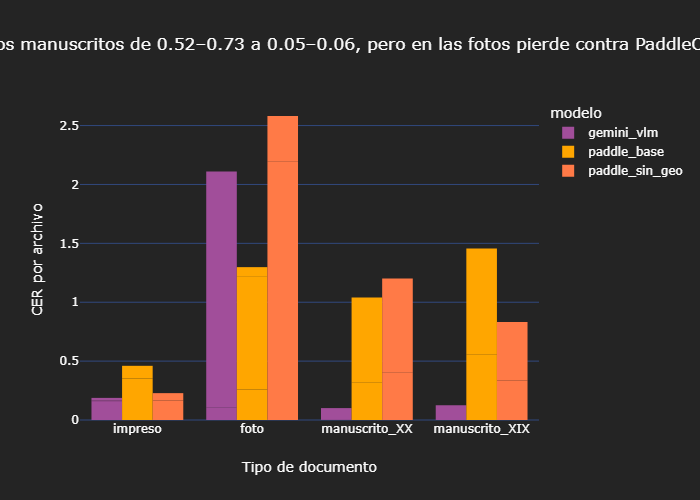

In [10]:
fig = px.bar(det[det.modelo.isin(cer_t.modelo)], x="estrato", y="valor", color="modelo", barmode="group",
             color_discrete_map=paleta.COLORES_MODELO, labels={"valor": "CER por archivo", "estrato": "Tipo de documento"},
             category_orders={"estrato": ["impreso", "foto", "manuscrito_XX", "manuscrito_XIX"]},
             title=TITULO_CER)
fig.show()

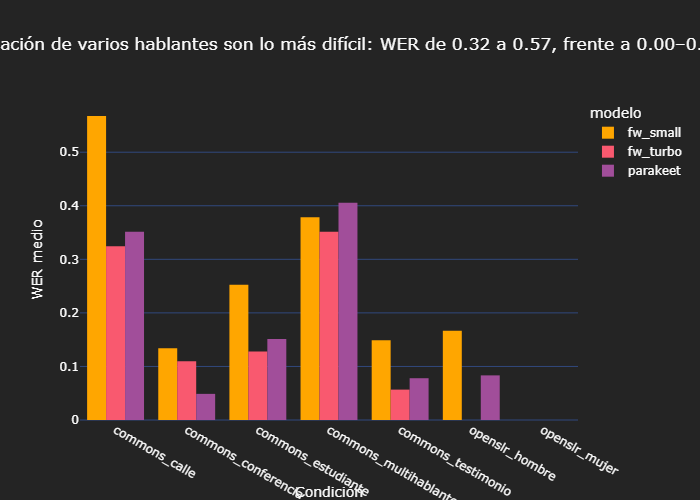

In [11]:
cond = det[det.modelo.isin(wer_t.modelo)].copy()
fig = px.bar(cond.groupby(["estrato", "modelo"], as_index=False).valor.mean(), x="estrato", y="valor", color="modelo",
             barmode="group", color_discrete_map=paleta.COLORES_MODELO, labels={"valor": "WER medio", "estrato": "Condición"},
             title=TITULO_WER)
fig.show()

In [12]:
# Alineación de un manuscrito: qué tipo de error comete el OCR (texto seudonimizado)
peor = det[(det.modelo == "paddle_base") & det.estrato.str.startswith("manuscrito")].sort_values("valor").iloc[-1]
h = p_ocr[(p_ocr.id == peor.id) & (p_ocr.modelo == "paddle_base")].texto.fillna("").iloc[0]
salida = jiwer.process_characters(ocr.limpiar_para_metrica(pv.seudonimizar(ref[peor.id], reemplazos)[0])[:400],
                                  ocr.limpiar_para_metrica(pv.seudonimizar(h, reemplazos)[0])[:400] or "∅")
print(peor.id, peor.estrato, "CER", round(peor.valor, 3))
print("sustituciones", salida.substitutions, "| borrados", salida.deletions, "| inserciones", salida.insertions)
print(jiwer.visualize_alignment(salida, show_measures=False)[:1500])

doc_024 manuscrito_XIX CER 0.902
sustituciones 2 | borrados 265 | inserciones 0
=== SENTENCE 1 ===

REF: exmo sr d agustín gamarra doce de agosto de mil ochocientos cuarenta mi respetable gral y padrino sin embargo de hallarme bien enfermo con la disenteria q he contraido en mi confi nacion de huancayo me he situado en este pueblo en cumplimto de la orden supre ma si mi mal como es probable se agra
HYP: **m******************************************i* ***************re*******r**petable h*al y*padrino *************************************************t*******************************************u*****************************px*************************************************************************
     DD DDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDD D DDDDDDDDDDDDDDD  DDDDDDD DD        SD    D        DDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDD DDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDD DDDDDDDDDDDDDDDDDDDDDDDDDDDDD SDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDDD

In [13]:
# Alucinación: los 5 tramos más largos que el VAD considera silencio, tanto en contexto como aislados
aluc = pd.DataFrame(json.loads((RAW / "asr" / "alucinacion.json").read_text(encoding="utf-8")))
aluc["segundos"] = (aluc.fin - aluc.inicio).round(1)
print(f"small SIN VAD produce texto en {(aluc.sin_vad != '').sum()} de {len(aluc)} tramos sin voz; "
      f"CON VAD, en {(aluc.con_vad != '').sum()}")
aluc[["grabacion", "inicio", "fin", "segundos", "sin_vad", "con_vad"]]

small SIN VAD produce texto en 4 de 5 tramos sin voz; CON VAD, en 0


,grabacion,inicio,fin,segundos,sin_vad,con_vad
0,rec_01,47.62,53.46,5.8,"en cuevas, en cuevas, orejas, en orejitas",
1,rec_03,91.56,93.85,2.3,¡Suscríbete!,
2,rec_06,62.18,64.44,2.3,,
3,rec_02,69.42,71.45,2.0,¡Suscríbete!,
4,rec_02,142.44,144.38,1.9,¡Suscríbete!,


## 7. Comparativa y decisión

,modalidad,modelo,agregado,media_por_archivo,seg_por_archivo,rtf,carga_seg,cer_lineas_ordenadas,costo
0,OCR (CER),gemini_vlm,0.138,0.252,22.773,NaN,NaN,0.442447,API en la nube (envía la imagen)
1,OCR (CER),paddle_base,0.310,0.426,7.700,NaN,NaN,0.535671,"local, CPU"
2,OCR (CER),paddle_sin_geo,0.323,0.484,7.478,NaN,NaN,0.538918,"local, CPU"
3,ASR (WER),fw_small,0.224,0.207,25.809,1.017,3.1,NaN,"local, CPU · 244 M parámetros"
4,ASR (WER),fw_turbo,0.125,0.110,62.347,2.537,7.7,NaN,"local, CPU · 809 M parámetros"
5,ASR (WER),parakeet,0.139,0.135,7.362,0.271,27.3,NaN,"local, CPU · 600 M parámetros"


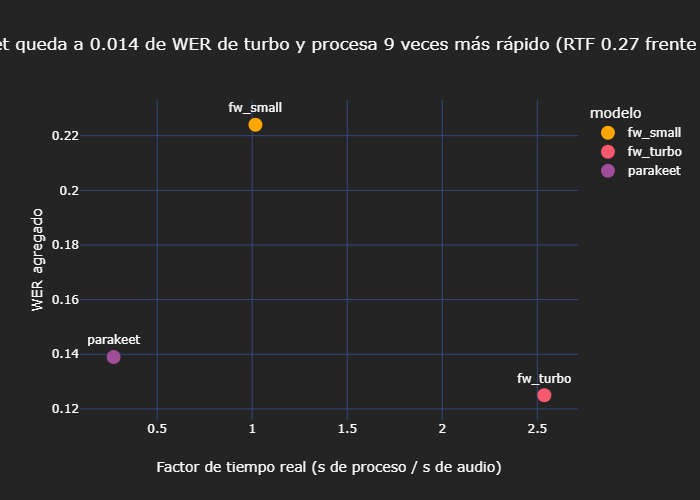

In [14]:
cer_t["modalidad"], wer_t["modalidad"] = "OCR (CER)", "ASR (WER)"
costo = {"paddle_base": "local, CPU", "paddle_sin_geo": "local, CPU", "gemini_vlm": "API en la nube (envía la imagen)",
         "fw_small": "local, CPU · 244 M parámetros", "fw_turbo": "local, CPU · 809 M parámetros", "parakeet": "local, CPU · 600 M parámetros"}
comparativa = pd.concat([cer_t, wer_t], ignore_index=True)
comparativa["costo"] = comparativa.modelo.map(costo)
cols = ["modalidad", "modelo", "agregado", "media_por_archivo", "seg_por_archivo", "rtf", "carga_seg", "cer_lineas_ordenadas", "costo"]
display(comparativa.reindex(columns=cols))
fig = px.scatter(wer_t, x="rtf", y="agregado", text="modelo", color="modelo", color_discrete_map=paleta.COLORES_MODELO,
                 labels={"rtf": "Factor de tiempo real (s de proceso / s de audio)", "agregado": "WER agregado"},
                 title=TITULO_RTF)
fig.update_traces(textposition="top center", marker_size=14)
fig.show()

In [15]:
def elegir(t, baratos):
    t = t.sort_values("agregado")
    mejor = t.iloc[0]
    empatados = t[t.agregado - mejor.agregado < 0.02]
    for m in baratos:
        if m in set(empatados.modelo):
            return t.set_index("modelo").loc[m]
    return mejor
fin_ocr = elegir(cer_t, ["paddle_base", "paddle_sin_geo", "gemini_vlm"])
fin_asr = elegir(wer_t, ["fw_small", "parakeet", "fw_turbo"])
print("Regla congelada:", config["regla_de_decision"])
print(f"Modelo final OCR: {fin_ocr.name} (CER {fin_ocr.agregado:.3f}) | Modelo final ASR: {fin_asr.name} (WER {fin_asr.agregado:.3f})")

Regla congelada: modelo final por modalidad = menor CER/WER agregado; si la diferencia es < 0.02, el más barato (local antes que API; menor RTF)
Modelo final OCR: gemini_vlm (CER 0.138) | Modelo final ASR: parakeet (WER 0.139)


## Decisión y reflexión

**Decisión** (regla congelada antes de medir):
- **OCR → Gemini como VLM** (CER agregado 0.138, frente a 0.310 de la línea base PaddleOCR). La diferencia supera con creces el umbral de 0.02, así que la regla no deja lugar al desempate por costo.
- **ASR → Parakeet TDT 0.6B v3** (WER 0.139). turbo obtiene 0.125, pero la diferencia (0.014) es menor que 0.02, y la regla elige entonces el más barato: Parakeet procesa unas 9 veces más rápido (RTF 0.27 frente a 2.54) en la misma CPU. La línea base `small` queda en 0.224.

**Documentos: dónde funcionó mejor o peor, y por qué**
- **Impresos nítidos:** todos los modelos van bien (CER medio de 0.06 a 0.15). Es el caso para el que PaddleOCR está entrenado: tipografía regular y renglones horizontales.
- **Manuscritos:** aquí está la brecha. PaddleOCR obtiene 0.52 (siglo XX) y 0.73 (siglo XIX), y casi todo su error son **borrados**: en doc_024 hay 265 caracteres borrados y solo 2 sustituciones. El detector no encuentra los renglones de la letra cursiva, y lo que detecta, el reconocedor (entrenado con texto impreso) no lo lee. Gemini, que lee la imagen completa como un modelo de visión y lenguaje, baja a 0.05–0.06.
- **Fotos:** es el único tipo en el que Gemini pierde (0.70 frente a 0.43). El promedio lo arrastra **doc_014**, la vitrina con la matriz de plomo y el primer ejemplar de *El Peruano*: Gemini obtiene CER 1.7, es decir, más de un error por carácter de la referencia, porque **agrega** texto. Hace dos cosas:
  1. Transcribe la letra pequeña del periódico, que en la referencia manual quedó como `[?]` porque a simple vista no se lee con seguridad.
  2. **Repite un bloque entero** ("NUM. 1 SEMESTRE… LOS EDITORES" aparece dos veces). Probablemente "lee" también la matriz de plomo, que tiene el mismo texto en espejo.

  Es la cara opuesta del manuscrito: un VLM produce texto fluido aunque no sea lo que está escrito en esa región, y eso no se nota sin una referencia.
- **Ablación de la corrección geométrica** (`paddle_sin_geo`): sin orientación ni *unwarping*, las fotos empeoran mucho (0.86 frente a 0.43). En cambio, los impresos planos (0.08 frente a 0.15) y los manuscritos del siglo XIX (0.42 frente a 0.73) mejoran. El *unwarping* ayuda donde hay perspectiva y deforma lo que ya estaba plano.

**Audio: dónde funcionó mejor o peor, y por qué**
- **Lectura limpia** (OpenSLR, micrófono cercano, una oración): WER de 0.00 a 0.17. Turbo y Parakeet casi no fallan.
- **Calle** (rec_01) y **conversación de varios hablantes** (rec_02): WER de 0.32 a 0.57 en los tres modelos. Hay ruido de tránsito, voces superpuestas y frases cortadas. Ningún modelo más grande lo resuelve, porque el problema está en la señal.
- **Conferencia de prensa:** Parakeet es el mejor (0.05), con una sola voz y un micrófono de prensa.
- **Alucinación:** sobre 5 tramos que el VAD considera silencio (en contexto y aislados), `small` **sin VAD** escribe texto en 4. En 3 de ellos es la clásica frase "¡Suscríbete!", que Whisper aprendió de subtítulos de YouTube. **Con VAD**, no escribe nada en ninguno. Por eso el VAD va siempre activado.

**Cómputo y latencia**
- Todo corre en una laptop sin GPU (CPU de 12 hilos).
- **PaddleOCR:** ~8 s por recorte, local y gratis.
- **Gemini:** ~23 s por recorte, con la latencia de la API. Además, envía la imagen a un tercero: para documentos con datos personales, el OCR local es la opción por privacidad, aunque lea peor.
- **ASR:** Parakeet tarda más en cargar (27 s, frente a 3 s de `small`), pero después es el más rápido. Para un archivo de horas de audio, lo que pesa es el RTF.

**Recomendación (no es la métrica final):** un esquema **híbrido**. PaddleOCR local para impresos y fotos de impresos (barato, sin enviar datos). Gemini solo para manuscritos, donde la diferencia es de 0.5 de CER. Y en ASR, Parakeet con VAD.

**Auditoría del LLM:**
- **11 de 20 extracciones (55 %) quedaron completamente correctas**, pero la cifra junta dos dificultades distintas:

  | | Casos completos | Campos correctos |
  |---|---|---|
  | Documentos (8 campos) | 3/10 | 63/80 |
  | Audios (5 campos) | 8/10 | 48/50 |
  | Total | 11/20 | 111/130 (85 %) |

  Por tipo de documento: impresos 2/3, fotos 0/3, manuscritos del siglo XX 1/1 y del siglo XIX 0/3.
- **El LLM leyó el texto de la línea base**, no el de los modelos finales: el OCR de PaddleOCR y el ASR de `small`, porque Gemini solo leyó los 10 recortes de la evaluación. En los manuscritos del siglo XIX ese texto ya llega muy degradado: PaddleOCR tiene un CER de 0.73 en los de la muestra.
- **Dos modos de falla** en los 17 campos incorrectos de documentos:
  - **8 omisiones:** `null` donde el dato aparece. Por ejemplo, el monto "$30" de doc_021, el destinatario de doc_014 y el tipo de documento de doc_004. Las reglas del prompt contra inventar ("si un dato no aparece, usa null") empujan al modelo hacia el `null`. Aparecen en impresos, fotos y manuscritos, y cada una de las tres fotos tiene al menos una.
  - **8 correcciones, inferencias o recortes**, todos en los manuscritos del siglo XIX. El modelo:
    - "corrige" grafías (Areguipa → Arequipa);
    - infiere el emisor a partir de una despedida y el día a partir de una fecha ilegible;
    - recorta la fecha y la firma de doc_025 a un fragmento.
  - El campo restante es un tema que nombra la publicación en lugar del asunto (doc_014).

  En audio, los 2 errores son resúmenes que agregan o atribuyen algo que el texto no dice.
- **Las citas y el número de hablantes salieron siempre bien.** Pero el número de hablantes es correcto por construcción: la regla pide contar las marcas `[HABLANTE_n]`, así que mide si el modelo cuenta etiquetas, no cuántas personas hablan. La diarización vio 1 hablante en rec_02, donde hay 3.
- **El chequeo automático de literalidad (96 %) no detecta estos errores.** No reemplaza la auditoría:
  - no revisa los `null`, así que las omisiones son invisibles;
  - tampoco revisa el tema, el resumen ni el tipo de documento;
  - `partial_ratio` acepta un fragmento recortado como si fuera el valor completo.

  De los 9 casos que fallaron en la auditoría, 6 tienen 100 % de literalidad.
- **Qué se está midiendo:**
  - 18 de los 20 casos auditados los hizo `gemini-3.5-flash-lite`, el último respaldo de la cadena. La política de reintentos es corta (2 intentos, de 4 y 8 s, antes de pasar al respaldo): privilegia terminar sobre la consistencia del modelo.
  - La muestra sobrerrepresenta las entrevistas (7 de los 33 clips de Commons, frente a 3 de los 120 de OpenSLR), así que el 11/20 no es una estimación de todo el corpus.

**Límites y desvíos declarados**
- **n = 10 por modalidad:** un solo documento (doc_014) invierte el resultado de las fotos. Las cifras son indicativas y optimistas.
- **Modelos de Gemini:** los modelos 3.8 y 3.7 Flash respondieron 503 (saturados), así que se usaron los respaldos de la cadena congelada:
  - **OCR:** 8 recortes con `gemini-3.6-flash` y 2 (los manuscritos del siglo XIX) con `gemini-3.5-flash-lite`;
  - **extracción:** 170 de 178 con `gemini-3.5-flash-lite`.

  El modelo usado queda registrado fila por fila.
- **Las transcripciones publicadas del corpus son de `small`.** Se eligió antes de medir, por cómputo: turbo proyectaba más de una hora de CPU. La evaluación recomienda Parakeet. Retranscribir los 40 minutos con Parakeet costaría ~11 minutos de CPU y queda como siguiente paso.
- **La decisión de ASR depende de cómo se promedia.** Con el WER agregado, que es la métrica oficial, turbo y Parakeet quedan a 0.014 y gana Parakeet por costo. Con la media por archivo (0.110 frente a 0.135), la diferencia es de 0.025: supera el umbral y ganaría turbo. La decisión se mantiene porque el agregado se fijó como métrica oficial en `configuraciones.json` antes de medir. Aun así, es frágil: con 10 clips, el desempate depende de cómo se pondera cada archivo. En OCR no pasa: Gemini gana con los dos promedios (0.252 frente a 0.426 por archivo).
- **El CER con líneas ordenadas no cumple su propósito.** Debía separar el error de orden de lectura del error de reconocimiento, pero sale más alto que el agregado (0.44 para Gemini, 0.54 para PaddleOCR), porque los modelos no cortan las líneas donde las corta la referencia. En doc_004, por ejemplo, la referencia tiene 19 líneas y Gemini devuelve 9. Al ordenarlas, las líneas quedan desalineadas. No cambia el orden de los modelos, pero no permite medir cuánto del error se debe al orden de lectura.


## 8. Bonus: NER peruano y "quién dijo qué"

C:\Users\DOKU\Documents\GitHub\intermediate-python-hw\tarea_2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 19890.53it/s]


[transformers] BertForTokenClassification LOAD REPORT from: mrm8488/bert-spanish-cased-finetuned-ner
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


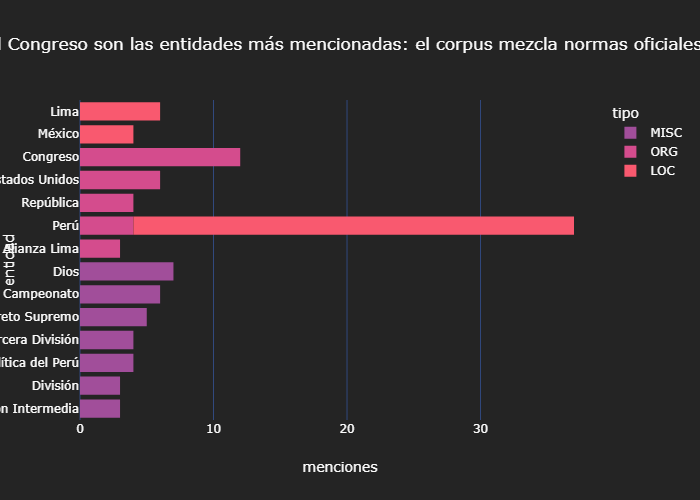

In [16]:
from transformers import pipeline
ner = pipeline("ner", model="mrm8488/bert-spanish-cased-finetuned-ner", aggregation_strategy="simple")
docs_pub = pd.read_csv(RAIZ / "datos" / "documentos.csv")
trans_pub = pd.read_csv(RAIZ / "datos" / "transcripciones.csv")
ent = []
for mod, df, col in [("documento", docs_pub, "texto_ocr"), ("audio", trans_pub, "texto_asr")]:
    for i, t in zip(df.id, df[col].fillna("")):
        for trozo in pv._trozos(t):
            for e in ner(trozo):
                if e["score"] >= 0.7 and e["entity_group"] in {"ORG", "LOC", "MISC"} and len(e["word"]) > 2:
                    ent.append({"id": i, "modalidad": mod, "tipo": e["entity_group"], "entidad": e["word"].strip()})
ent = pd.DataFrame(ent)
ent.to_csv(RAIZ / "datos" / "ner_entidades.csv", index=False)
top = ent.groupby(["entidad", "tipo"]).size().reset_index(name="menciones").nlargest(15, "menciones")
fig = px.bar(top.sort_values("menciones"), x="menciones", y="entidad", color="tipo", orientation="h",
             color_discrete_sequence=paleta.RAMPA[3:], title=TITULO_NER)
fig.show()

In [17]:
# "Quién dijo qué" en los clips multihablante (cualitativo: el hablante viene de la diarización; no hay verdad de terreno)
multi = trans_pub[trans_pub.n_hablantes >= 2].id
for i in multi[:3]:
    campos = json.loads(ext.set_index("id").campos_json[i])
    print(i, "→", [(c["hablante"], c["cita"][:80]) for c in campos.get("citas_clave", [])])

clip_001 → [('HABLANTE_2', '[PERSONA_11].'), ('HABLANTE_2', 'Bueno, esperamos que Perú ganemos, ¿no? Espero que Padula se eche goles.')]
clip_002 → [('HABLANTE_1', '¿Quién gana y a cuánto? ¿Por cuánto?'), ('HABLANTE_2', 'Es que esperar lo que Dios, primeramente es Dios, pero si perdemos a mí hay que ')]
clip_003 → [('HABLANTE_2', 'Que Perú gane.')]


## 9. Exportación y resultados para la entrega

In [18]:
# texto_referencia (seudonimizado) solo en los 10 + 10 de la muestra
docs_pub["texto_referencia"] = docs_pub.id.map({i: pv.seudonimizar(ref[i], reemplazos)[0] for i in ids_doc if i in ref}).fillna("")
docs_pub["region_eval"] = np.where(docs_pub.id.isin(ids_doc), "superior_40", "")
trans_pub["texto_referencia"] = trans_pub.id.map({i: pv.seudonimizar(ref[i], reemplazos)[0] for i in ids_aud if i in ref}).fillna("")
docs_pub.to_csv(RAIZ / "datos" / "documentos.csv", index=False)
trans_pub.to_csv(RAIZ / "datos" / "transcripciones.csv", index=False)
p_ocr.assign(texto=[pv.seudonimizar(t, reemplazos)[0] for t in p_ocr.texto.fillna("")])[["id", "modelo", "texto", "segundos"]] \
    .to_csv(RAIZ / "datos" / "predicciones_ocr.csv", index=False)
p_asr.assign(texto=[pv.seudonimizar(t, reemplazos)[0] for t in p_asr.texto.fillna("")])[["id", "modelo", "texto", "segundos", "rtf"]] \
    .to_csv(RAIZ / "datos" / "predicciones_asr.csv", index=False)
det.to_csv(RAIZ / "datos" / "metricas_por_archivo.csv", index=False)
metricas = {
    "documentos_procesados": int(len(docs_pub)), "minutos_audio": round(float(trans_pub.duracion_seg.sum()) / 60, 1),
    "clips": int(len(trans_pub)), "cer": cer_t.set_index("modelo").agregado.round(3).to_dict(),
    "wer": wer_t.set_index("modelo").agregado.round(3).to_dict(), "rtf": wer_t.set_index("modelo").rtf.round(3).to_dict(),
    "linea_base": {"cer": round(float(base_cer), 3), "wer": round(float(base_wer), 3)},
    "final": {"ocr": fin_ocr.name, "cer": round(float(fin_ocr.agregado), 3), "asr": fin_asr.name, "wer": round(float(fin_asr.agregado), 3)},
    "acuerdo_llm_humano": {"correctas": n_ok, "total": n}, "literalidad": {"ok": int(ok), "total": int(tot)},
}
(RAIZ / "modelos" / "metricas.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Resultados Test: WER: {fin_asr.agregado:.2f} | CER: {fin_ocr.agregado:.2f} | Acuerdo LLM-Humano: {n_ok}/{n}")

Resultados Test: WER: 0.14 | CER: 0.14 | Acuerdo LLM-Humano: 11/20
